# 02 · Edge detection and threshold segmentation

**Owner:** Member A · **Labs:** 3 (Sobel, Prewitt, Canny) and 5 (global and adaptive thresholding) ·
**Requirements:** REQ-02, REQ-11; spec Sections 8.4–8.6 and 15.4.

### Objective
* Compare gradient operators and Canny threshold pairs on the same ROI (edge fraction, fragmentation, continuity).
* Compare the four mandatory threshold methods — fixed, Otsu, adaptive mean, adaptive Gaussian (block 15/31/51).
* Build conservative hair / visible-scalp / flake / unknown **candidate** masks and show their failure cases.

Edges locate transitions; they do not identify follicles. Masks are heuristic candidates: agreement between two
threshold methods is not accuracy. Pixel precision/recall is reported **only** on synthetic fixtures with known truth.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Robust project-root discovery: works from notebooks/ or the project root, installed or not.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "default.yaml").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scalptrack.config import load_config, seed_everything, project_path, display_path
from scalptrack.demo_data import dataset_status, development_images, synthetic_closeups, figure_path
import cv2
from scalptrack import edges, segmentation as sg
from scalptrack.preprocessing import to_gray, signed_to_display
from scalptrack.demo_data import mask_precision_recall
from scalptrack.viz import show_grid

cfg = load_config()
rng = seed_everything(cfg["seed"])
NB = "02_edges_segmentation"
rel = lambda p: display_path(p, ROOT)  # noqa: E731 - short path for printing
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
print("project root:", ROOT)
print("config:", Path(cfg["config_path"]).name, "| seed:", cfg["seed"])

project root: C:\Riddhi_Projects\ScalpTrack
config: default.yaml | seed: 42


In [2]:
def save_fig(fig, name, provenance):
    """Save under outputs/figures/<NB>/<real|synthetic>/ ; synthetic figures get a caption and SYNTHETIC_ prefix."""
    from scalptrack.viz import synthetic_banner
    if provenance == "synthetic":
        synthetic_banner(fig)
    p = figure_path(cfg, NB, name, provenance)
    fig.savefig(p, dpi=120, bbox_inches="tight")
    print("saved", rel(p))
    return p

In [3]:
STATUS = dataset_status(cfg)
print(STATUS["message"])
REAL = STATUS["available"]
DEV = development_images(cfg, n_per_class=1, max_total=4) if REAL else []
SYN = synthetic_closeups(cfg)
print(f"real development images loaded: {len(DEV)} (train/validation only) | synthetic fixtures: {list(SYN)}")

REAL DATASET NOT AVAILABLE - synthetic fixtures are used below.
Dataset 'kaggle_hair_diseases' was not found or contains no images.
Download it from https://www.kaggle.com/datasets/sundarannamalai/hair-diseases (license: CC BY-NC-SA 4.0) and extract it so that:
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\train\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\val\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\test\<Class Name>\*.jpg
  (or, without a publisher split: C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<Class Name>\*.jpg)
See docs/dataset_setup.md for step-by-step instructions.
real development images loaded: 0 (train/validation only) | synthetic fixtures: ['clean', 'flakes', 'shadow', 'glare', 'light_hair', 'blurred']


In [4]:
INPUTS = [(d["rgb"], d["image_id"], "real") for d in DEV[:2]] + [(SYN["flakes"]["rgb"], "flakes", "synthetic")]
print("edge parameters:", cfg["edges"])

edge parameters: {'sobel_ksize': 3, 'gradient_threshold_fraction': 0.25, 'canny_blur_ksize': 5, 'canny_blur_sigma': 1.2, 'canny_pairs': [[30, 90], [50, 150], [80, 200]]}


## 1. Lab 3 — Sobel and Prewitt gradients
Prewitt uses explicit kernels through `cv2.filter2D` (correlation). Signed derivatives are shown with a symmetric
diverging scale; only display copies are normalised.

,x-1,x,x+1
Prewitt Gx,,,
0,-1.0,0.0,1.0
1,-1.0,0.0,1.0
2,-1.0,0.0,1.0


,x-1,x,x+1
Prewitt Gy,,,
0,-1.0,-1.0,-1.0
1,0.0,0.0,0.0
2,1.0,1.0,1.0


saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_gradients_flakes.png


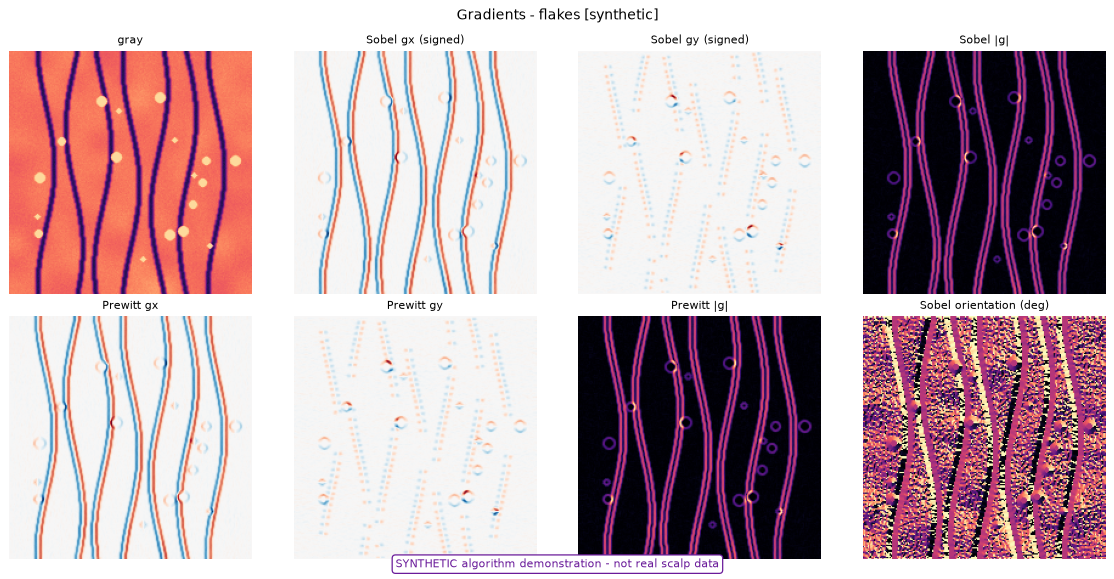

In [5]:
display(pd.DataFrame(edges.PREWITT_X, columns=["x-1", "x", "x+1"]).rename_axis("Prewitt Gx"))
display(pd.DataFrame(edges.PREWITT_Y, columns=["x-1", "x", "x+1"]).rename_axis("Prewitt Gy"))
for rgb, name, prov in INPUTS:
    gray = to_gray(rgb)
    sob, pre = edges.sobel_gradients(gray, cfg["edges"]["sobel_ksize"]), edges.prewitt_gradients(gray)
    fig = show_grid([gray, sob["gx"], sob["gy"], sob["magnitude"], pre["gx"], pre["gy"], pre["magnitude"],
                     np.rad2deg(sob["orientation"])],
                    ["gray", "Sobel gx (signed)", "Sobel gy (signed)", "Sobel |g|", "Prewitt gx", "Prewitt gy",
                     "Prewitt |g|", "Sobel orientation (deg)"],
                    ncols=4, signed={1, 2, 4, 5}, cmap="magma", suptitle=f"Gradients - {name} [{prov}]")
    save_fig(fig, f"gradients_{name}", prov); plt.show()

## 2. Canny with several threshold pairs, and binary comparison
Sobel/Prewitt magnitudes are binarised at a documented fraction of their maximum
(`gradient_threshold_fraction`) before they are compared with Canny's binary output.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_edge_maps_flakes.png


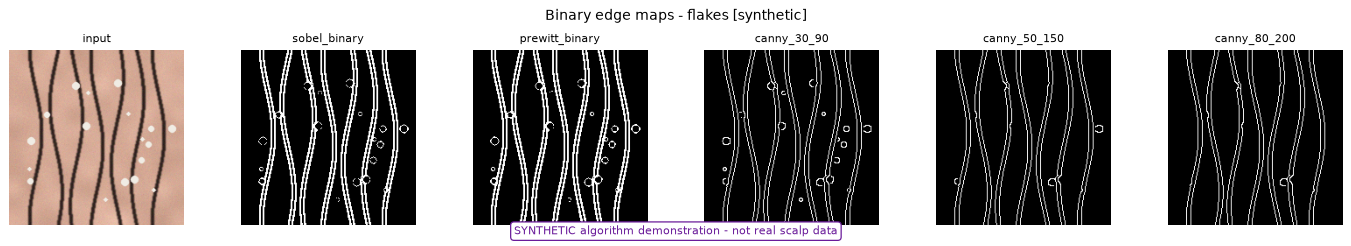

,image,provenance,map,edge_fraction,n_fragments,mean_fragment_px,frac_fragments_le_5px
0,flakes,synthetic,sobel_binary,0.1658,33,201.0000,0.5152
1,flakes,synthetic,prewitt_binary,0.1686,19,354.8421,0.2632
2,flakes,synthetic,canny_30_90,0.0783,31,101.0000,0.0968
3,flakes,synthetic,canny_50_150,0.0723,15,192.8667,0.0000
4,flakes,synthetic,canny_80_200,0.0713,13,219.3846,0.0000


In [6]:
summ = []
for rgb, name, prov in INPUTS:
    res = edges.compare_edges(to_gray(rgb), cfg)
    maps = res["binary_maps"]
    fig = show_grid([rgb] + list(maps.values()), ["input"] + list(maps), ncols=6, size=2.6,
                    suptitle=f"Binary edge maps - {name} [{prov}]")
    save_fig(fig, f"edge_maps_{name}", prov); plt.show()
    for k, v in res["summary"].items():
        summ.append({"image": name, "provenance": prov, "map": k, **v})
edge_table = pd.DataFrame(summ)
edge_table.to_csv(project_path(cfg, "results", NB, "edge_summary.csv", create=True), index=False)
edge_table.round(4)

Low Canny thresholds respond to background skin texture (many small fragments); high thresholds keep only strong
shaft boundaries but break them into pieces. The profile below shows that **one shaft produces two Canny edges**,
so edge pixels or edge fragments cannot be used as a hair count.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_canny_two_edges_per_shaft.png


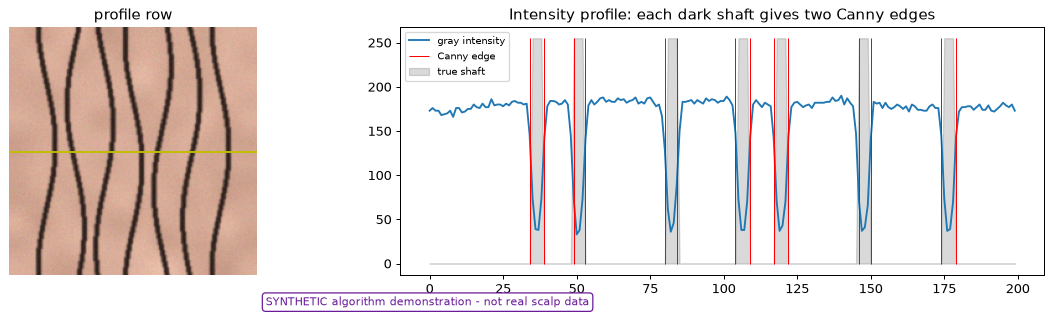

shafts crossing this row: 7 | Canny edge pixels on the row: 14


In [7]:
rgb = SYN["clean"]["rgb"]; gray = to_gray(rgb)
can = edges.canny(gray, *cfg["edges"]["canny_pairs"][1], cfg["edges"]["canny_blur_ksize"], cfg["edges"]["canny_blur_sigma"])
row = gray.shape[0] // 2
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].imshow(rgb); ax[0].axhline(row, color="y"); ax[0].set_title("profile row"); ax[0].axis("off")
ax[1].plot(gray[row], label="gray intensity")
ax[1].vlines(np.nonzero(can[row])[0], 0, 255, colors="r", lw=0.8, label="Canny edge")
ax[1].fill_between(np.arange(gray.shape[1]), 0, 255 * SYN["clean"]["hair_truth"][row], color="k", alpha=.15, label="true shaft")
ax[1].legend(fontsize=8); ax[1].set_title("Intensity profile: each dark shaft gives two Canny edges")
plt.tight_layout(); save_fig(fig, "canny_two_edges_per_shaft", "synthetic"); plt.show()
runs = np.diff(np.concatenate([[0], SYN["clean"]["hair_truth"][row].astype(int), [0]]))
print(f"shafts crossing this row: {(runs == 1).sum()} | Canny edge pixels on the row: {int(can[row].sum())}")

## 3. Lab 5 — fixed, Otsu, adaptive mean and adaptive Gaussian thresholds
Inverse thresholding selects **dark** pixels (hair candidates). Block sizes must be odd and > 1; sizes larger than
the ROI are skipped and reported. The constant C is subtracted from the local (weighted) mean.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_threshold_overlays_flakes.png


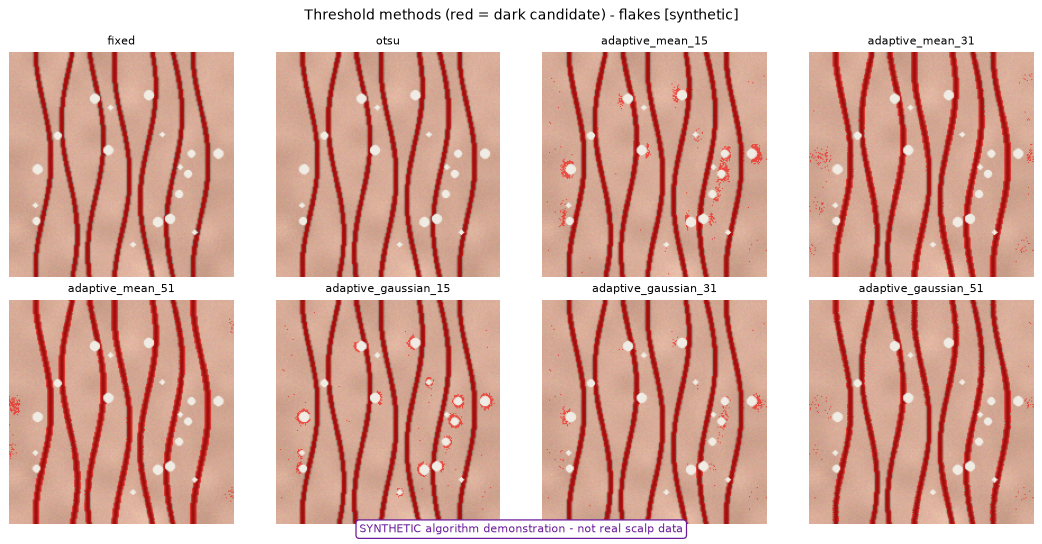

,image,provenance,method,threshold,inverse,foreground_fraction,precision,recall,f1,block_size,C
0,flakes,synthetic,fixed,90.0,True,0.136,1.000,0.957,0.978,NaN,NaN
1,flakes,synthetic,otsu,117.0,True,0.140,0.999,0.986,0.992,NaN,NaN
2,flakes,synthetic,adaptive_mean_15,NaN,True,0.166,0.843,0.988,0.910,15.0,8.0
3,flakes,synthetic,adaptive_mean_31,NaN,True,0.193,0.724,0.988,0.836,31.0,8.0
4,flakes,synthetic,adaptive_mean_51,NaN,True,0.199,0.704,0.987,0.822,51.0,8.0
5,flakes,synthetic,adaptive_gaussian_15,NaN,True,0.154,0.911,0.987,0.948,15.0,8.0
6,flakes,synthetic,adaptive_gaussian_31,NaN,True,0.156,0.900,0.988,0.942,31.0,8.0
7,flakes,synthetic,adaptive_gaussian_51,NaN,True,0.174,0.803,0.988,0.886,51.0,8.0


In [8]:
frac_rows = []
for rgb, name, prov in INPUTS:
    res = sg.compare_thresholds(to_gray(rgb), cfg, inverse=True)
    names = list(res["masks"])
    fig = show_grid([sg.overlay_mask(rgb, res["masks"][k], (255, 0, 0), .55) for k in names], names, ncols=4, size=3,
                    suptitle=f"Threshold methods (red = dark candidate) - {name} [{prov}]")
    save_fig(fig, f"threshold_overlays_{name}", prov); plt.show()
    for k in names:
        row = {"image": name, "provenance": prov, "method": k, **res["params"][k], "foreground_fraction": res["foreground_fraction"][k]}
        if prov == "synthetic":
            row.update(mask_precision_recall(res["masks"][k], SYN["flakes"]["hair_truth"]))
        frac_rows.append(row)
    if res["skipped_block_sizes"]:
        print(name, "skipped block sizes:", res["skipped_block_sizes"])
thr_table = pd.DataFrame(frac_rows)
thr_table.to_csv(project_path(cfg, "results", NB, "threshold_comparison.csv", create=True), index=False)
thr_table.round(3)

Precision/recall columns exist only for the synthetic image, where the true shaft mask is known. On real images
the table only reports foreground fractions.

### 3.1 Development selection of block size and C (adaptive Gaussian + cleanup)
The hair-mask parameters are selected by **mean F1 over all synthetic development fixtures** (the six close-ups
including shadow/glare/light-hair/blur, plus two extra seeds), not on one image and never on test data. The
result is written into `configs/default.yaml`; the cell checks that the configuration matches the selection.

In [9]:
from scalptrack import synthetic as syn
dev_cases = {k: (v["rgb"], v["hair_truth"]) for k, v in SYN.items()}
for s in (7, 8):
    m = syn.curved_shafts(9, 3.0, seed=s, size=200)["mask"]
    dev_cases[f"extra_seed{s}"] = (syn.render_hair_image(m, seed=s), m)
rows = []
for bs in (15, 31, 51):
    for C in (3, 5, 8, 10, 12, 15):
        c2 = {**cfg, "segmentation": {**cfg["segmentation"], "hair_block_size": bs, "adaptive_c": C}}
        f1 = {k: (mask_precision_recall(sg.segment_candidates(rgb, c2)["hair"], t)["f1"] or 0.0) for k, (rgb, t) in dev_cases.items()}
        rows.append({"block_size": bs, "C": C, **f1, "mean_f1": float(np.mean(list(f1.values())))})
sweep = pd.DataFrame(rows).sort_values("mean_f1", ascending=False)
sweep.to_csv(project_path(cfg, "results", NB, "SYNTHETIC_adaptive_selection.csv", create=True), index=False)
display(sweep.head(8).round(3))
best = sweep.iloc[0]
chosen = (int(best["block_size"]), float(best["C"]))
configured = (cfg["segmentation"]["hair_block_size"], float(cfg["segmentation"]["adaptive_c"]))
print("selected on development fixtures:", chosen, "| configured:", configured,
      "| MATCH" if chosen == configured else "| MISMATCH - update configs/default.yaml")

,block_size,C,clean,flakes,shadow,glare,light_hair,blurred,extra_seed7,extra_seed8,mean_f1
2,15,8,1.000,0.958,0.855,1.000,0.934,0.878,0.999,0.999,0.953
1,15,5,1.000,0.914,0.846,1.000,0.984,0.811,0.994,0.994,0.943
11,31,15,0.991,0.979,0.828,0.990,0.906,0.869,0.969,0.970,0.938
3,15,10,1.000,0.979,0.856,1.000,0.860,0.771,1.000,1.000,0.933
10,31,12,0.978,0.968,0.813,0.977,0.971,0.820,0.967,0.967,0.933
9,31,10,0.973,0.959,0.805,0.973,0.989,0.783,0.960,0.959,0.925
8,31,8,0.969,0.946,0.798,0.970,0.995,0.748,0.942,0.939,0.913
17,51,15,0.966,0.949,0.783,0.965,0.970,0.776,0.932,0.927,0.908


selected on development fixtures: (15, 8.0) | configured: (15, 8.0) | MATCH


The winning block (15 px) is small because the synthetic shafts are only 3–4 px wide; an adaptive block must be
several times wider than a shaft or the shaft interior is compared against itself. On real close-ups with wider
shafts this choice must be re-checked on development images (block ≥ ≈3× the apparent shaft width). Note how
`C` trades recall on light hair against precision on shadow/blur — there is no setting that wins every case.

## 4. Conservative cleanup — before and after
Opening with a 3×3 kernel erases 1–2 px shafts, so it is off by default. A small closing bridges single-pixel gaps;
small components are removed. Both effects are shown, and their influence on width is measured in notebook 04.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_cleanup_before_after.png


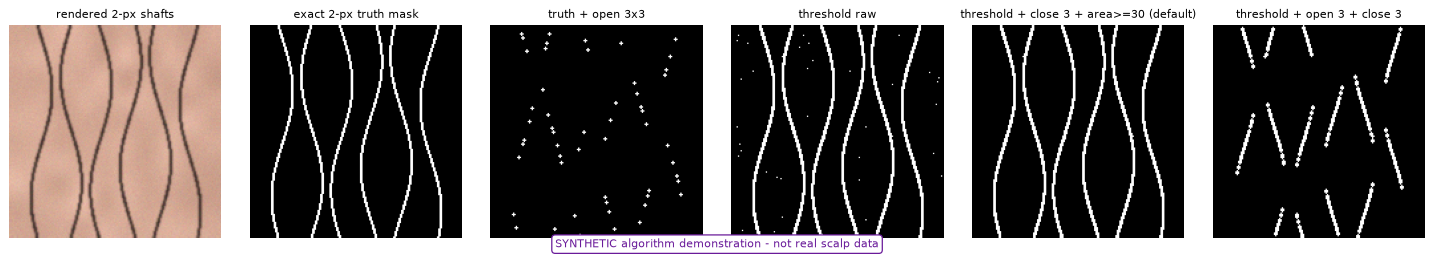

,variant,pixels,precision,recall,f1
0,exact 2-px truth mask,1973,1.000,1.000,1.000
1,truth + open 3x3,265,1.000,0.134,0.237
2,threshold raw,2379,0.829,1.000,0.907
3,threshold + close 3 + area>=30 (default),2345,0.841,1.000,0.914
4,threshold + open 3 + close 3,1306,0.774,0.512,0.617


In [10]:
truth = syn.curved_shafts(6, 2.0, seed=4)["mask"]
thin = syn.render_hair_image(truth, seed=4)
raw = sg.threshold_adaptive(to_gray(thin), "gaussian", cfg["segmentation"]["hair_block_size"], cfg["segmentation"]["adaptive_c"])
k, a = cfg["segmentation"]["close_kernel"], cfg["segmentation"]["min_component_area"]
variants = {
    "exact 2-px truth mask": truth,
    "truth + open 3x3": sg.cleanup_mask(truth, 3, 0, 1),
    "threshold raw": raw,
    f"threshold + close {k} + area>={a} (default)": sg.cleanup_mask(raw, 0, k, a),
    f"threshold + open 3 + close {k}": sg.cleanup_mask(raw, 3, k, a),
}
fig = show_grid([thin] + list(variants.values()), ["rendered 2-px shafts"] + list(variants), ncols=6, size=2.7)
save_fig(fig, "cleanup_before_after", "synthetic"); plt.show()
pd.DataFrame([{"variant": n, "pixels": int(v.sum()), **mask_precision_recall(v, truth)} for n, v in variants.items()]).round(3)

Applied to an exact 2-px mask, a 3×3 opening removes almost every shaft pixel (recall collapses). After
thresholding the rendered image the candidate shafts are already wider than 2 px (blur spreads the dark profile),
so opening does less damage there — but it still removes thin ends, which is why it stays disabled by default.

## 5. Candidate masks: hair, visible scalp, flakes, unknown
Priority: unknown (deep shadow or saturated colourless glare) > hair > flake > scalp, so the four masks are disjoint.
Flakes are bright, locally prominent, low-saturation blobs within an area range.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_candidate_masks_flakes.png


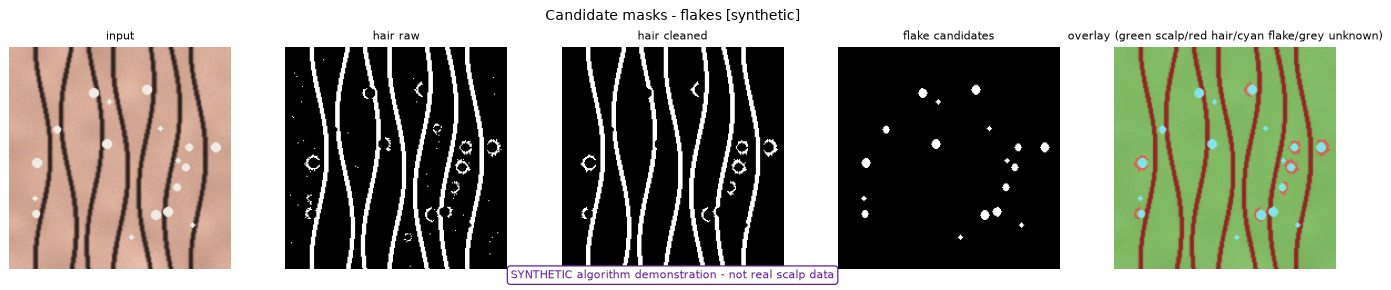

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_candidate_masks_clean.png


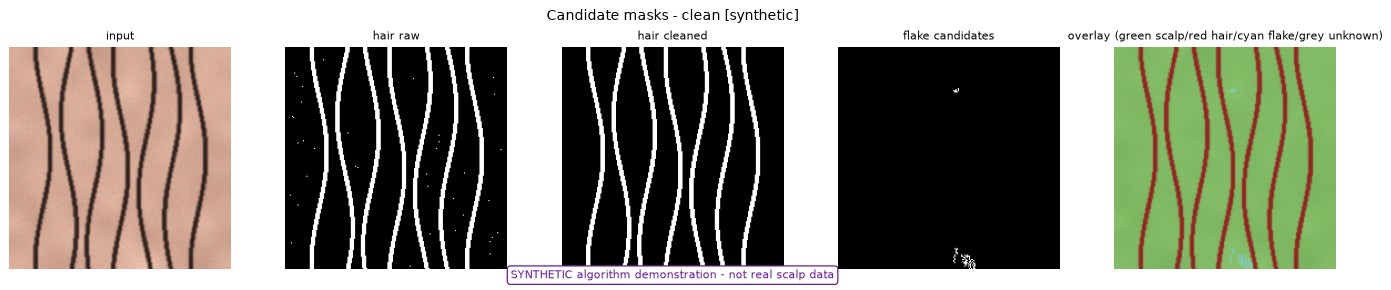

,image,provenance,visible_scalp_fraction,hair_coverage_fraction,scalp_to_hair_area_ratio,flake_candidate_coverage,excluded_fraction,unit
0,flakes,synthetic,0.8473,0.1527,5.5485,0.0153,0.0,pixel-area fraction
1,clean,synthetic,0.8579,0.1421,6.0381,0.0022,0.0,pixel-area fraction


In [11]:
colors = {"hair": (230, 40, 40), "flake": (40, 220, 255), "unknown": (90, 90, 90), "scalp": (60, 200, 60)}
cov_rows = []
for rgb, name, prov in INPUTS + [(SYN["clean"]["rgb"], "clean", "synthetic")]:
    seg = sg.segment_candidates(rgb, cfg)
    ov = sg.label_overlay(rgb, {k: seg[k] for k in ("scalp", "hair", "flake", "unknown")}, colors)
    fig = show_grid([rgb, seg["hair_raw"], seg["hair"], seg["flake"], ov],
                    ["input", "hair raw", "hair cleaned", "flake candidates", "overlay (green scalp/red hair/cyan flake/grey unknown)"],
                    ncols=5, size=3.1, suptitle=f"Candidate masks - {name} [{prov}]")
    save_fig(fig, f"candidate_masks_{name}", prov); plt.show()
    cov = sg.coverage_descriptors(seg["hair"], seg["scalp"], seg["flake"], ~seg["unknown"])
    cov_rows.append({"image": name, "provenance": prov, **cov})
pd.DataFrame(cov_rows).round(4)

Coverage values are **pixel-area fractions** of candidate masks — not hairs/cm² and not a clinical dandruff
percentage. `None` means the denominator was empty.

## 6. Failure cases (spec Section 15.4)
Each synthetic case has a known truth mask, so the failure is measured, not just shown.

saved outputs/figures/02_edges_segmentation/synthetic/SYNTHETIC_failure_cases.png


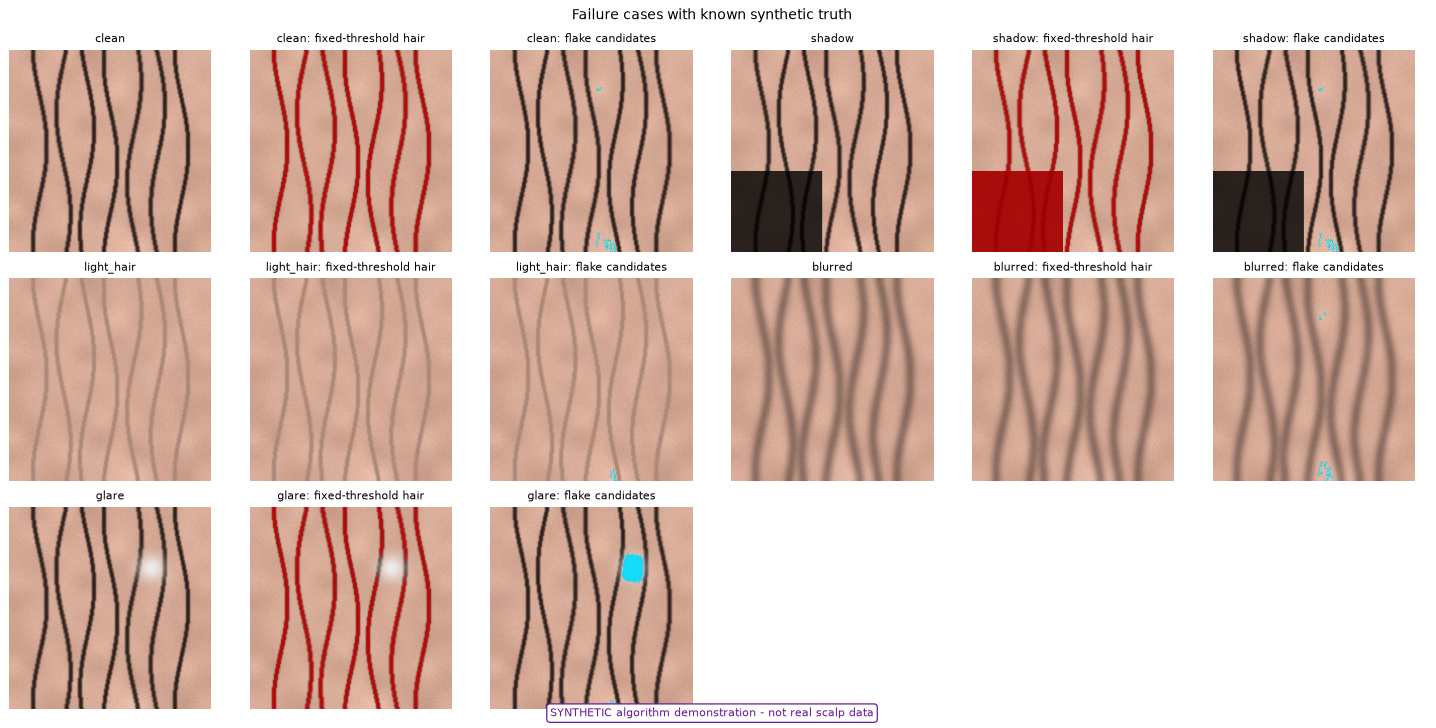

,fixed: precision,fixed: recall,otsu: precision,adaptive+cleanup: precision,adaptive+cleanup: recall,flake candidates (px),unknown (px)
case,,,,,,,
clean,1.00,0.972,0.999,1.000,1.000,87,0
shadow,0.47,0.974,0.477,0.884,0.828,88,973
light_hair,NaN,0.000,0.933,1.000,0.876,28,0
blurred,NaN,0.000,0.406,0.861,0.896,85,0
glare,1.00,0.943,0.999,1.000,1.000,534,0


shadow     : fixed-threshold precision 0.47 (clean 1.00) -> shadowed skin is labelled as hair; adaptive precision 0.88
light hair : fixed-threshold recall 0.00 (clean 0.97) -> the dark global threshold misses low-contrast shafts
blur       : fixed recall 0.00; adaptive precision 0.86 -> widened, faded shafts
glare      : 534 flake-candidate px vs 87 on the flake-free clean image -> glare passes the brightness/saturation flake test


In [12]:
rows, panels, titles = [], [], []
for case in ("clean", "shadow", "light_hair", "blurred", "glare"):
    rgb = SYN[case]["rgb"]; truth = SYN[case]["hair_truth"]
    seg = sg.segment_candidates(rgb, cfg)
    otsu, _ = sg.threshold_otsu(to_gray(rgb))
    fixed = sg.threshold_fixed(to_gray(rgb), cfg["segmentation"]["fixed_threshold"])
    rows.append({"case": case,
                 "fixed: precision": mask_precision_recall(fixed, truth)["precision"],
                 "fixed: recall": mask_precision_recall(fixed, truth)["recall"],
                 "otsu: precision": mask_precision_recall(otsu, truth)["precision"],
                 "adaptive+cleanup: precision": mask_precision_recall(seg["hair"], truth)["precision"],
                 "adaptive+cleanup: recall": mask_precision_recall(seg["hair"], truth)["recall"],
                 "flake candidates (px)": int(seg["flake"].sum()), "unknown (px)": int(seg["unknown"].sum())})
    panels += [rgb, sg.overlay_mask(rgb, fixed, (255, 0, 0), .6), sg.overlay_mask(rgb, seg["flake"], (0, 220, 255), .9)]
    titles += [case, f"{case}: fixed-threshold hair", f"{case}: flake candidates"]
fig = show_grid(panels, titles, ncols=6, size=2.7, suptitle="Failure cases with known synthetic truth")
save_fig(fig, "failure_cases", "synthetic"); plt.show()
fail = pd.DataFrame(rows).set_index("case")
fail.to_csv(project_path(cfg, "results", NB, "SYNTHETIC_failure_cases.csv", create=True))
display(fail.round(3))
# Statements below are computed from the table, not written in advance.
f = fail.fillna(0)
print(f"shadow     : fixed-threshold precision {f.loc['shadow', 'fixed: precision']:.2f} (clean {f.loc['clean', 'fixed: precision']:.2f}) "
      f"-> shadowed skin is labelled as hair; adaptive precision {f.loc['shadow', 'adaptive+cleanup: precision']:.2f}")
print(f"light hair : fixed-threshold recall {f.loc['light_hair', 'fixed: recall']:.2f} (clean {f.loc['clean', 'fixed: recall']:.2f}) "
      f"-> the dark global threshold misses low-contrast shafts")
print(f"blur       : fixed recall {f.loc['blurred', 'fixed: recall']:.2f}; adaptive precision {f.loc['blurred', 'adaptive+cleanup: precision']:.2f} "
      f"-> widened, faded shafts")
print(f"glare      : {int(f.loc['glare', 'flake candidates (px)'])} flake-candidate px vs {int(f.loc['clean', 'flake candidates (px)'])} "
      f"on the flake-free clean image -> glare passes the brightness/saturation flake test")

**Reading the table.**
* *Shadow:* a fixed global threshold turns dark shadowed skin into "hair". Adaptive thresholding compares against
  the local mean and is less affected; very deep shadow is moved to *unknown*.
* *Light/grey hair:* low contrast against skin — the fixed dark threshold misses it entirely. Otsu/adaptive adapt
  to this synthetic image, but real grey hair on pale skin can defeat them too.
* *Blur:* shafts widen and fade; the quality gate (Laplacian variance) flags such ROIs before measurement (notebook 04).
* *Glare:* the highlight produces **false flake candidates**. Even the flake-free clean image has a few candidates
  from bright noise peaks — flake coverage is a candidate descriptor, not a dandruff measurement.

## 7. Limitations
* No ground-truth masks exist for the public images; real overlays are qualitative.
* The chosen method (adaptive Gaussian, block 31, C 5, closing 3) was tuned on synthetic/development images and may
  fail on other lighting, hair colours or magnifications.
* Dice/IoU between two threshold methods is not reported, because neither is ground truth.

## 8. Conclusion
Sobel and Prewitt give similar magnitudes (Sobel weights the centre row more); Canny gives thin, connected
boundaries whose density depends strongly on its thresholds. Among thresholds, adaptive methods are robust to
illumination gradients but sensitive to C and block size. Functions: `scalptrack.edges`, `scalptrack.segmentation`.

**References:** OpenCV image filtering and thresholding tutorials (spec Section 24.2, refs 1 and 3).